# First cosmological analysis: inferring ($\sigma_8, b_g$) from galaxy auto and galaxy x cmb lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/test_box_x/results/`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/test_box_x/results)/`.
    - The galaxies auto-spectrum $C_{\ell}^{gg}$ and kappa $\times$ galaxies cross-spectrum $C_{\ell}^{\kappa g}$ can be found in `./data/test_box_x/cls/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameters in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import camb
import healpy as hp

from scipy.optimize import minimize
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus, corner

import json
import sys
sys.path.append('../')

from utils.rebinning import hybrid_bin_cls, make_hybrid_bin_matrix

# functions

## theory

In [2]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [3]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

In [4]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]

    bias = bz_interp(z)
    bias = np.where(np.isnan(bias), 0, bias)  # set nan bias to zero
    ndensity = nz_interp(z)
    ndensity = np.where(np.isnan(ndensity), 0, ndensity)  # set nan density to zero

    return bias * ndensity * (Hz / c_kms)

In [5]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

## data

In [6]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)

    return data['ells'], data['cls'], data['err'], data['nside'], data['shot_noise']

## fitting

In [7]:
def get_limber_cls_fit(
    params,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    sigma8_fid,
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, kp_gg, kp_kg, sigma8 = params

    # parameter-dependent smoothing
    smooth_gg = np.exp(-k2_grid / kp_gg**2)
    smooth_kg = np.exp(-k2_grid / kp_kg**2)

    # integrate over redshift
    cls_gg = simpson_weights @ (base_gg * smooth_gg)
    cls_kg = simpson_weights @ (base_kg * smooth_kg)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls_gg *= Abias**2 * growth_factor
    cls_kg *= Abias * growth_factor

    return cls_gg, cls_kg

In [8]:
def get_limber_cls_fit_gg(
    params,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
):
    '''
    Compute the angular gg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, kp, sigma8 = params

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias**2 * growth_factor

    return cls

In [9]:
def get_limber_cls_fit_kg(
    params,
    k2_grid,
    simpson_weights,
    base,
    sigma8_fid,
):
    '''
    Compute the angular kg power spectra using the Limber approximation.
    '''

    # fitting parameters
    Abias, kp, sigma8 = params

    # parameter-dependent smoothing
    smooth = np.exp(-k2_grid / kp**2)

    # integrate over redshift
    cls = simpson_weights @ (base * smooth)

    # sigma8 amplitude
    growth_factor = (sigma8 / sigma8_fid)**2

    cls *= Abias * growth_factor

    return cls

In [10]:
def get_chi2(
    params,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    cls_gg_theory, cls_kg_theory = get_limber_cls_fit(
        params,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        sigma8_fid
    )

    # rebin the theory to match the data
    cls_gg_theory = B_gg @ cls_gg_theory
    cls_kg_theory = B_kg @ cls_kg_theory

    # create theory vector
    cls_theory = np.concatenate((cls_gg_theory, cls_kg_theory))

    # residual
    residual = cls_data - cls_theory

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

In [11]:
def get_chi2_single(
    params,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
):
    '''
    Reduced chi-squared for gg and gk fitting.
    '''

    # compute theory
    cls_theory = get_limber_cls_fit_single(
        params,
        k2_grid,
        simpson_weights,
        base,
        sigma8_fid
    )

    # rebin the theory to match the data
    cls_theory = B @ cls_theory

    # residual
    residual = cls_data - cls_theory

    # get chi2 statistic
    chi2 = residual @ invcov_mat @ residual.T
    
    return chi2

## sampler

In [12]:
def log_prior(theta):
    '''
    Flat priors on A_bias, kp and sigma8.
    '''

    Abias, kp_gg, kp_kg, sigma8 = theta

    if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5 and 0.05 < kp_gg < 1.0 and 0.05 < kp_kg < 1.0:
        return 0.0

    return -np.inf

In [13]:
def log_prior_single(theta):
    '''
    Flat priors on A_bias, kp and sigma8 for the single dataset of gg/kg.
    Priors are more restrictive than for the joint dataset, since the single dataset is less constraining and we want to avoid unphysical values of the parameters.
    Moreover, we need the contours to have enough resolution to be able to plot them in the joint corner plot, so we need to restrict the parameter space to a reasonable range.
    '''

    Abias, kp, sigma8 = theta

    #if 0.5 < sigma8 < 1.5 and 0.5 < Abias < 1.5 and 0.05 < kp < 1.0:
        #return 0.0

    # just visual plotting purposes
    if 0.78 < sigma8 < 0.84 and 0.94 < Abias < 1.08 and 0.05 < kp < 1.0:
        return 0.0

    return -np.inf

In [14]:
def log_posterior(
    theta,
    k2_grid,
    simpson_weights,
    base_gg,
    base_kg,
    B_gg,
    B_kg,
    cls_data,
    invcov_mat,
    sigma8_fid,
):

    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2(
        theta,
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
    )

    return lp - 0.5 * chi2

In [15]:
def log_posterior_single(
    theta,
    get_limber_cls_fit_single,
    k2_grid,
    simpson_weights,
    base,
    B,
    cls_data,
    invcov_mat,
    sigma8_fid,
):

    lp = log_prior_single(theta)
    if not np.isfinite(lp):
        return -np.inf

    chi2 = get_chi2_single(
        theta,
        get_limber_cls_fit_single,
        k2_grid,
        simpson_weights,
        base,
        B,
        cls_data,
        invcov_mat,
        sigma8_fid,
    )

    return lp - 0.5 * chi2

# Fitting sample

## choosing data

In [16]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'desi_qso'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
galaxy_catalog_bin = f'{galaxy_catalog}'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
params_path = f'../data/{box}/cosmo_params.json'

## measure and compare output n(z) with input n(z)

In [17]:
# load the galaxy bias distribution and create interpolator
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

# load the input n(z) histogram output from colore
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the output n(z) histogram output from colore
z_nz_output, nz_output = np.load(f'../data/{box}/cls/nz_{galaxy_catalog}.npz')['z_nz'], np.load(f'../data/{box}/cls/nz_{galaxy_catalog}.npz')['nz']
zbin_width_output = np.diff(z_nz_output)[0]

# load the bin output n(z) histogram output from colore
z_nz_output_bin, nz_output_bin = np.load(f'../data/{box}/cls/nz_{galaxy_catalog_bin}.npz')['z_nz'], np.load(f'../data/{box}/cls/nz_{galaxy_catalog_bin}.npz')['nz']
zbin_width_output_bin = np.diff(z_nz_output_bin)[0]
zmin_bin, zmax_bin = z_nz_output_bin[0], z_nz_output_bin[-1]
norm_output_bin = simpson(nz_output_bin, z_nz_output_bin)

In [18]:
# create n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_interp_input = PchipInterpolator(z_nz_input, nz_input * fsky, extrapolate=False)

# create n(z) interpolator for the output redshift distributions
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=False)
nz_interp_output_bin = PchipInterpolator(z_nz_output_bin, nz_output_bin/norm_output_bin, extrapolate=False)

In [19]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 500)

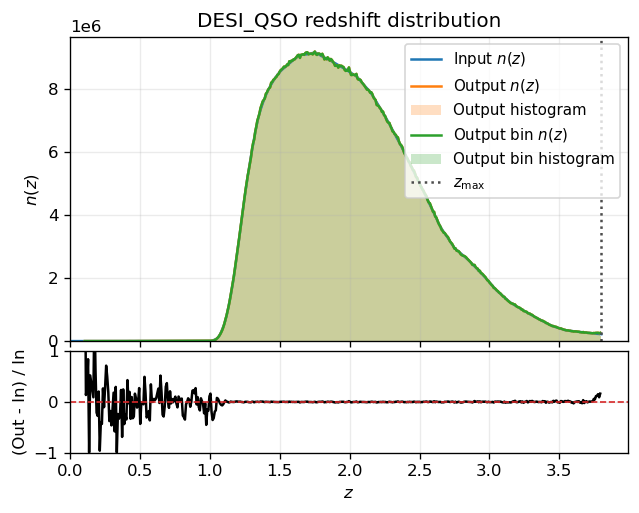

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.plot(z, nz_interp_input(z), 'C0-', lw=1.5, label=r'Input $n(z)$')
ax1.plot(z, nz_interp_output(z), 'C1-', lw=1.5, label=r'Output $n(z)$')
ax1.plot(z, nz_interp_output_bin(z)*norm_output_bin, 'C2-', lw=1.5, label=r'Output bin $n(z)$')
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C1', alpha=0.25, label='Output histogram')
ax1.bar(z_nz_output_bin, nz_output_bin, width=zbin_width_output_bin, align='center', color='C2', alpha=0.25, label='Output bin histogram') 

ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')
ax1.set_ylabel(r'$n(z)$')
ax1.set_title(f'{galaxy_catalog.upper()} redshift distribution')
ax1.grid(alpha=0.25)

handles, labels = ax1.get_legend_handles_labels()
order = [0, 1, 4, 2, 5, 3]
ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)

# Bottom panel
ratio = (nz_interp_output(z) - (nz_interp_input(z))) / nz_interp_input(z)
ratio[(nz_interp_input(z) == np.nan)] = np.nan # set to nan if nz_output is zero
ratio[(nz_interp_output(z) == np.nan)] = np.nan # set to nan if nz_output is zero
ax2.plot(z, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

plt.show()

# First analysis: $\sigma_8$ and $b_g$ fit

The plan is to infer $\sigma_8$ by breaking the degeneracy with galaxy bias $b(z)$ by combining galaxy auto and galaxy x cmb lensing spectrums. Marginalizing over $k_p$ for both galaxy auto and galaxy cross. However, we are working with $A_{\rm bias}$ instead of the bias directly, for validation purpouses, so we will be fitting for this parameter instead of the effective bias over the redshift bin $b_{\rm eff}$.

## preliminar

In [21]:
# set the fitting range for the chi2 minimization
lmin_fit = 20
lmax_fit = 1500  # L=1000 by default if NSIDE=1024
nbins_fit = 30   # nbins=30 by default if multipole range from L=20 to L=1000

In [22]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

In [23]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
z_max = cosmo_dict["z_max"]
sigma8_fid = cosmo_dict['sigma_8']

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=100,
    lmax=lmax,
    nonlinear=False
)

# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)

z_star = cosmo_dict["z_out"]
chi_star = results_lin.comoving_radial_distance(z_star)


# cosmological parameters needed by kernels
H0 = cosmo_dict["h"] * 100
om = cosmo_dict["omega_M"]

# shared kernel context
chi_source = chi_star
kernel_context = {
    "results": results_lin,
    "chi_source": chi_source,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 200)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin}

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context, kernel_args)
Wg_grid = W_g(z_grid, kernel_context, kernel_args)

## data and covariance

In [24]:
# load and rebin gg data
box_path_gg = f'../data/{box}/cls/cl_gg_{galaxy_catalog_bin}.npz'
ells_data, cls_gg_data, err_gg_data, nside_gg, shot_noise = get_colore_cls(box_path_gg)
ells_data_rebin, cls_gg_data_rebin, err_gg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_gg_data,
        err_gg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# load and rebin kg data
box_path_kg = f'../data/{box}/cls/cl_kg_{galaxy_catalog_bin}.npz'
ells_data, cls_kg_data, err_kg_data, nside_kg, shot_noise = get_colore_cls(box_path_kg)
ells_data_rebin, cls_kg_data_rebin, err_kg_data_rebin = hybrid_bin_cls(
        ells_data,
        cls_kg_data,
        err_kg_data,
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# smooth with healpix pixel window function
pixwin_gg = hp.pixwin(nside_gg)
pixwin_kg = hp.pixwin(nside_kg)

# create data array and covariance matrix
cls_data = np.concatenate((cls_gg_data_rebin, cls_kg_data_rebin))


/home/dljarque/Documents/cmb_lensing_lya/notebooks/../utils/rebinning.py:47: UserWarning: ell_min (20) >= ell_switch (20). Skipping linear binning and using logarithmic bins only.
  warnings.warn(


In [25]:
# compute and rebin covariance off-diagonal terms
fsky = 1
nl_gg = np.ones_like(ells_data) * shot_noise
ccov = (2 / ((2*ells_data[:lmax_fit] + 1)*fsky)) * ((cls_gg_data[:lmax_fit] + nl_gg[:lmax_fit]) * cls_kg_data[:lmax_fit])
_, _, ccov_rebin = hybrid_bin_cls(
        ells_data[:lmax_fit],
        np.zeros_like(ells_data[:lmax_fit]),
        np.sqrt(ccov[:lmax_fit]),
        nbins=nbins_fit,
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

# construct the covariance matrix between observables
var_gg_rebin = err_gg_data_rebin**2
var_kg_rebin = err_kg_data_rebin**2
ccov_rebin = ccov_rebin ** 2   # hybrid_bin_cls returns the standard deviations, but we need the correlation for the covariance matrix
rho_pearson = ccov_rebin/np.sqrt(var_gg_rebin * var_kg_rebin)  # Pearson correlation coefficient between gg and kg

cov_mat = np.block([[np.diag(var_gg_rebin), np.diag(ccov_rebin)],
                    [np.diag(ccov_rebin), np.diag(var_kg_rebin)]])
cov_mat_test = np.block([[np.diag(var_gg_rebin), np.zeros((nbins_fit, nbins_fit))],
                    [np.zeros((nbins_fit, nbins_fit)), np.diag(var_kg_rebin)]])

invcov_mat_gg = np.linalg.inv(np.diag(var_gg_rebin))
invcov_mat_kg = np.linalg.inv(np.diag(var_kg_rebin))
invcov_mat = np.linalg.inv(cov_mat)
invcov_mat_test = np.linalg.inv(cov_mat_test)

/tmp/ipykernel_35771/1827793482.py:8: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(ccov[:lmax_fit]),


In [26]:
# multipoles and cls
ells = np.arange(lmin_fit, lmax_fit + 1)

# geometry
chi = kernel_context["chi"][:, None]        # (Nz,1)
Hz = kernel_context["Hz"][:, None]          # (Nz,1)
c_kms = c * 1e-3

# Limber k-grid (Nz, Nell)
k_grid = (ells[None, :] + 0.5) / chi
k2_grid = k_grid**2

# valid CAMB region
kmax = 100.0
mask = (k_grid > 1e-4) & (k_grid < kmax)

# evaluate P(k,z) for all z and ell
pk_lin = np.zeros_like(k_grid)
pk_lin[mask] = pk_interp_lin.P(
    np.broadcast_to(z_grid[:, None], k_grid.shape)[mask],
    k_grid[mask],
    grid=False,
)

# integrand without smoothing
base_gg = pk_lin * (c_kms / Hz) * (Wg_grid[:, None] * Wg_grid[:, None]) / chi**2
base_kg = pk_lin * (c_kms / Hz) * (Wk_grid[:, None] * Wg_grid[:, None]) / chi**2

# match the healpix pixel window function with length of cls
lmax_map1 = len(pixwin_gg) - 1
lmax_map2 = len(pixwin_kg) - 1
lmax_min = np.min([lmax_map1, lmax_map2, lmax_fit])
pixwin_gg = pixwin_gg[lmin_fit : (lmax_min + 1)]
pixwin_kg = pixwin_kg[lmin_fit : (lmax_min + 1)]
ells = ells[:(lmax_min + 1 - lmin_fit)]

# rebin the theory to match the data
B = make_hybrid_bin_matrix(
    ells,
    nbins=nbins_fit,
    ell_min=lmin_fit,
    ell_max=lmax_fit,
)

# apply pixel window functions
B_gg = B * (pixwin_gg[None, :])**2
B_kg = B * (pixwin_kg[None, :])**2

In [27]:
# Exact weights corresponding to scipy.integrate.simpson(..., x=z_grid)
simpson_weights = np.zeros(len(z_grid))

for i in range(len(z_grid)):
    basis = np.zeros(len(z_grid))
    basis[i] = 1.0
    simpson_weights[i] = simpson(basis, x=z_grid)

## likelihood evaluation timer

In [28]:
x0 = [1.0, 0.3, 0.3, sigma8_fid]  # initial guess for Abias, kp_gg, kp_kg, and sigma8
niter = 100 # number of iterations for timing the posterior evaluation
start_x0 = x0 + 1e-1 * np.random.randn(niter, len(x0))  # generate random starting points for each iteration
t = []

import time

for i in range(niter):
    t0 = time.perf_counter()
    value = log_posterior(
            start_x0[i],
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_gg,
            B_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
        )
    t.append(time.perf_counter() - t0)

print(f"posterior evaluation: {np.mean(t):.5f} s")

posterior evaluation: 0.00374 s


In [29]:
test = [1.0, 0.3, 0.3, 0.81]
log_posterior(
            test,
            k2_grid,
            simpson_weights,
            base_gg,
            base_kg,
            B_gg,
            B_kg,
            cls_data,
            invcov_mat,
            sigma8_fid,
        )

np.float64(-519.504013006519)

In [30]:
test = [1.0, 0.3, 0.81]
log_posterior_single(
            test,
            get_limber_cls_fit_kg,
            k2_grid,
            simpson_weights,
            base_kg,
            B_kg,
            cls_kg_data_rebin,
            invcov_mat_kg,
            sigma8_fid,
        )

np.float64(-303.6760433476685)

## Full sample

### minimizer & sampler

In [31]:
# perform the chi2 minimization
x0 = [1.0, 0.3, 0.3, sigma8_fid]  # initial guess for Abias, kp_gg, kp_kg, and sigma8
bounds = [(0.5, 1.5), (0.05, 1.0), (0.05, 1.0), (0.5, 1.5)]  # bounds for Abias, kp_gg, kp_kg, and sigma8
result = minimize(
    get_chi2,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
    )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_kp_gg, best_kp_kg, best_sigma8  = result.x
cov = result.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result.fun/nbins_fit  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.3f} +/- {errors[-1]:.3f}")
print(f"Best-fit A_bias: {best_Abias:.3f} +/- {errors[0]:.3f}")
print(f"Best-fit kp_gg   : {best_kp_gg:.3f} +/- {errors[1]:.3f} 1/Mpc")
print(f"Best-fit kp_kg   : {best_kp_kg:.3f} +/- {errors[2]:.3f} 1/Mpc")
print(f"Reduced chi2 at best-fit: {chi2_best:.2f}")

Best-fit sigma8: 0.763 +/- 0.318
Best-fit A_bias: 1.080 +/- 0.472
Best-fit kp_gg   : 0.882 +/- 3.370 1/Mpc
Best-fit kp_kg   : 0.467 +/- 0.597 1/Mpc
Reduced chi2 at best-fit: 3.25


In [32]:
# scipy best fit as starting point for MCMC
theta0 = result.x

# initialize the MCMC
ndim = len(theta0)
nwalkers = 32  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter = theta0 * 0.01  # scatter for Abias, kp_gg, kp_kg, and sigma8

# initialize walkers around best fit
start = theta0 + scatter * np.random.randn(nwalkers, ndim)

In [33]:
# initialize the sampler
sampler = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior,
    args=(
        k2_grid,
        simpson_weights,
        base_gg,
        base_kg,
        B_gg,
        B_kg,
        cls_data,
        invcov_mat,
        sigma8_fid,
    ),
)

# run the MCMC
nsteps = 30000
sampler.run_mcmc(start, nsteps, progress=True) 

Initialising ensemble of 32 walkers...
Sampling progress : 100%|██████████| 30000/30000 [3:10:47<00:00,  2.62it/s]  


In [34]:
# save the chains to a file
raw_chain = sampler.get_chain()

map_idx = np.argmax(sampler.get_log_prob(flat=True))
map_estimate = sampler.get_chain(flat=True)[map_idx]

truths = np.array([1.0, best_kp_gg, best_kp_kg, sigma8_fid])  # Assuming the true value of A_bias is 1.0 for the purpose of this example
np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", 
         chain=raw_chain, nsteps=nsteps, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit, 
         map_estimate=map_estimate, bestfit_values=result.x, true_values=truths)

### visualization

In [36]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'desi_qso'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 30000  # number of steps for MCMC

chain_file = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", allow_pickle=True)

chain = chain_file['chain']
nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
map_estimate = chain_file['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

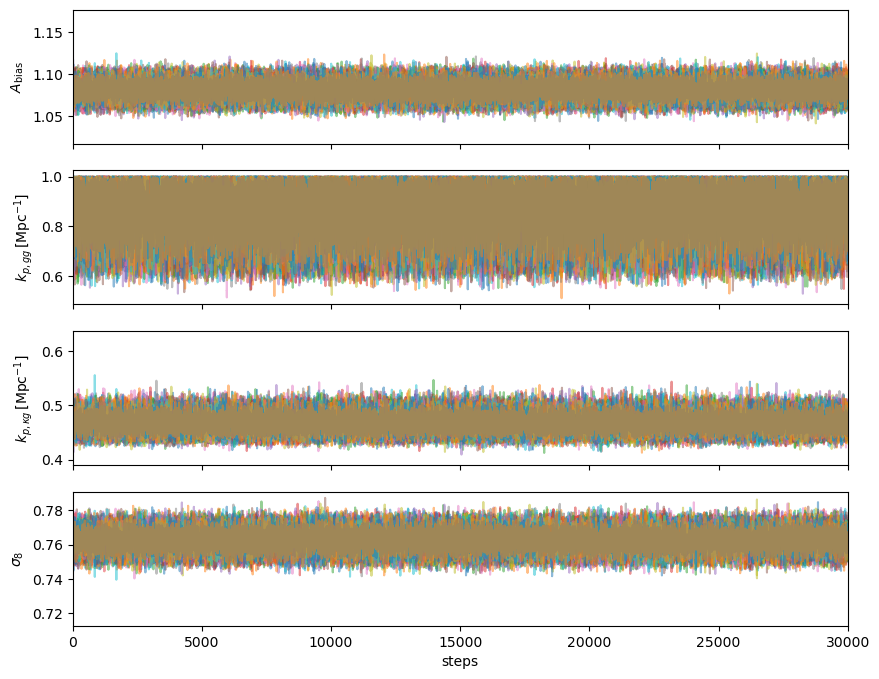

In [37]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$k_{p,gg}\,[\mathrm{Mpc}^{-1}]$",
    r"$k_{p,\kappa g}\,[\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

for i in range(ndim):
    for walker in range(chain.shape[1]):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, len(chain))
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [38]:
chain[200, :, -1]

array([0.75625542, 0.76533168, 0.76421766, 0.76203345, 0.76697358,
       0.76017775, 0.75752019, 0.76111038, 0.75026928, 0.76739342,
       0.76333388, 0.7573023 , 0.77495822, 0.76071086, 0.76076965,
       0.75783585, 0.75926185, 0.7689821 , 0.76387455, 0.75751694,
       0.76436695, 0.76956245, 0.75732725, 0.76526914, 0.76283934,
       0.76549674, 0.75496714, 0.75977582, 0.75901823, 0.75817099,
       0.76453948, 0.76537458])

In [39]:
burnin = 250
deleted_walkers = np.array([]).astype(int)  # indices of walkers to delete

clean_chain = np.delete(chain, obj=deleted_walkers, axis=1)
clean_chain = clean_chain[burnin:, : , :]  # discard the first burnin steps as burn-in
clean_samples = clean_chain.reshape(-1, clean_chain.shape[-1])  # reshape to 2D array for corner plot

np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", 
         chain=chain, clean_samples=clean_samples, nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers, ndim=ndim, 
         map_estimate=map_estimate, bestfit_values=bestfit_values, true_values=truths)

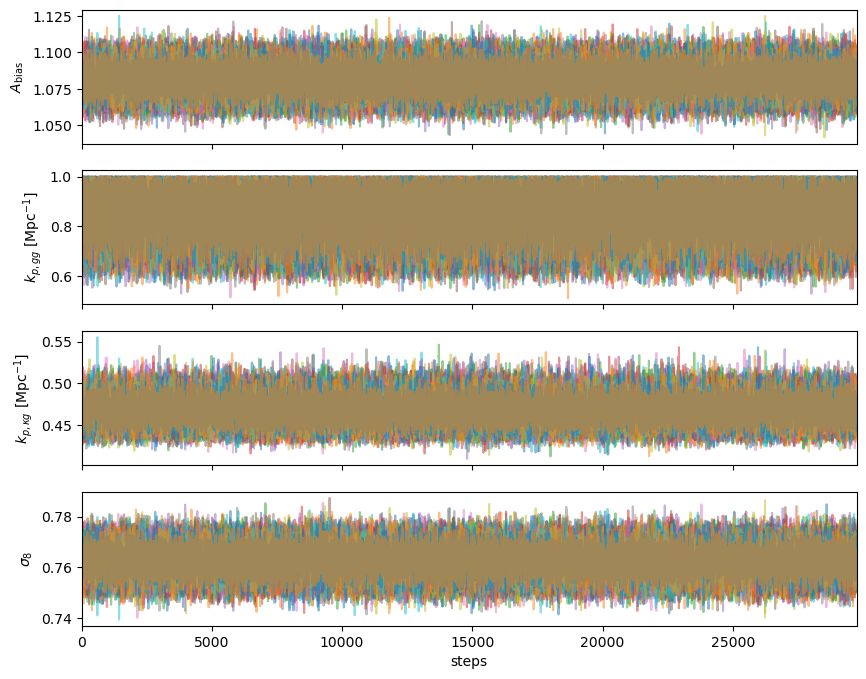

In [40]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)
axis_labels = [
    r"$A_{\rm bias}$",
    r"$k_{p,gg} \ [\mathrm{Mpc}^{-1}]$",
    r"$k_{p,\kappa g} \ [\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

for i in range(ndim):
    for walker in range(nwalkers-len(deleted_walkers)):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(clean_chain[:, walker, i], alpha=0.5)
    ax.set_xlim(0, clean_chain.shape[0])
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

### plotter

In [43]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'desi_qso'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps = 30000  # number of steps for MCMC

chain_file = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_joint_nsteps{nsteps}.npz", allow_pickle=True)

chain = chain_file['chain']
samples = chain_file['clean_samples']

nsteps = chain_file['nsteps']
nwalkers = chain_file['nwalkers']
ndim = chain_file['ndim']
deleted_walkers = chain_file['deleted_walkers']
burnin = chain_file['burnin']

map_estimate = chain_file['map_estimate']
bestfit_values = chain_file['bestfit_values']
truths = chain_file['true_values']

In [42]:
nsteps_single = 30000  # number of steps for MCMC
chain_file_gg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']

FileNotFoundError: [Errno 2] No such file or directory: '../data/test_box_4/chains/chain_desi_qso_gg_nsteps30000_constrained.npz'

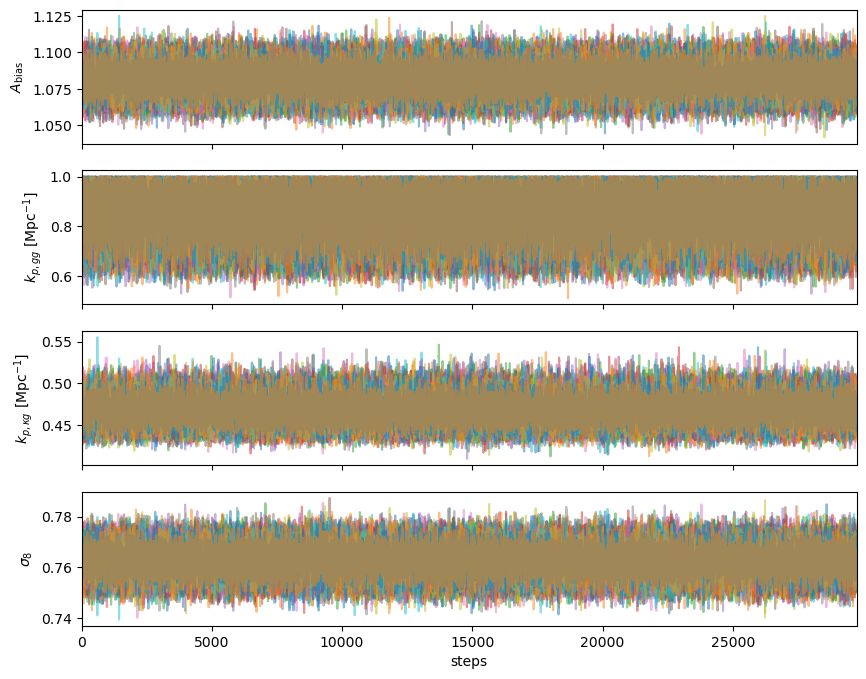

In [44]:
axis_labels = [
    r"$A_{\rm bias}$",
    r"$k_{p,gg} \ [\mathrm{Mpc}^{-1}]$",
    r"$k_{p,\kappa g} \ [\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)

for i in range(ndim):
    for walker in np.delete(np.arange(nwalkers), deleted_walkers):
        ax = axes[i]
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain[burnin:, walker, i], alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels[i])
    axes[-1].set_xlabel('steps')

In [45]:
# 1σ and 2σ enclosed probabilities for a 2D Gaussian
levels = [
    1.0 - np.exp(-0.5),  # 1σ ≈ 0.393
    1.0 - np.exp(-2.0),  # 2σ ≈ 0.865
]

nbins=100  # number of bins for the histograms in the corner plot (50x50 grid for 2D histograms = 2500 pixels)
smooth=0.0  # gaussian smoothing for the 2D histograms in the corner plot (0.0 = no smoothing)
smooth1d=0.0  # gaussian smoothing for the 1D histograms in the corner plot (0.0 = no smoothing)

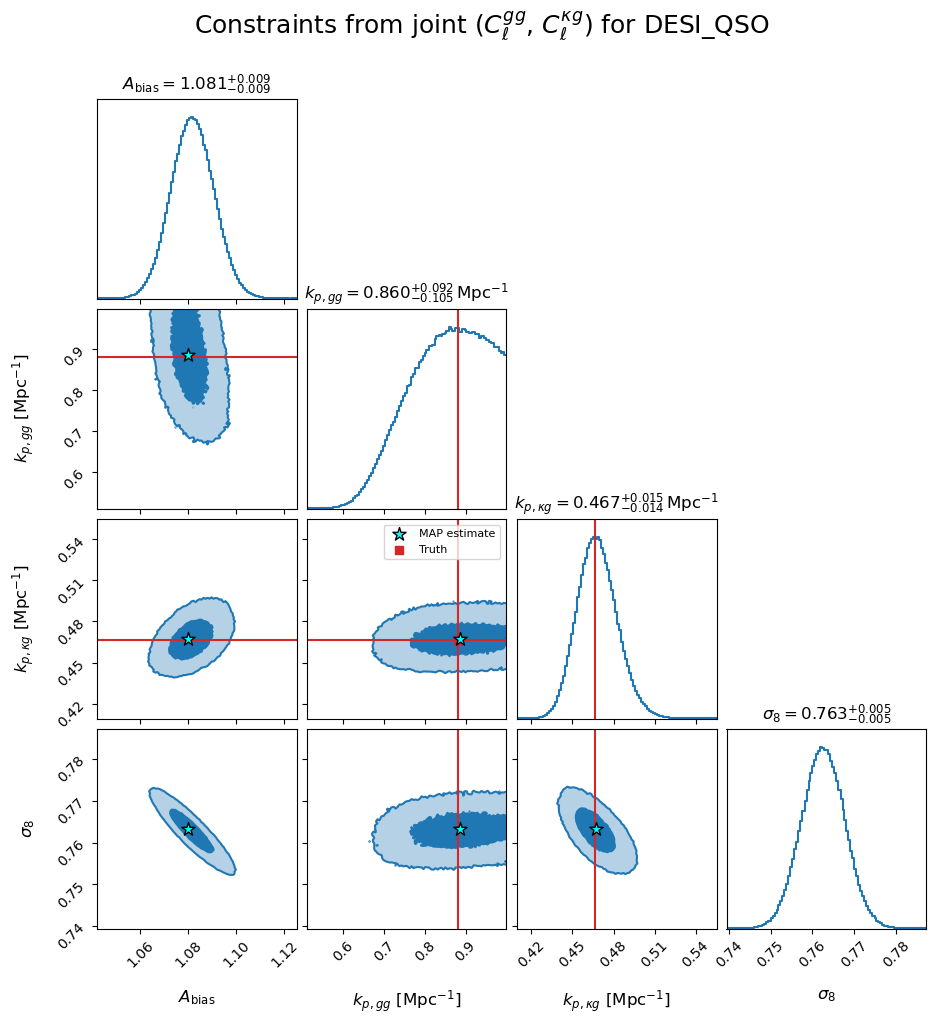

In [46]:
fig = corner.corner(
    samples,
    labels=axis_labels,
    # Only show truths for sigma8 and Abias
    truths=truths,
    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C0",
    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},
    # Samples / contours
    plot_datapoints=False,
    plot_density=False,
    # Truth lines
    truth_color="tab:red",
    # Histograms
    hist_kwargs={
        "linewidth": 1.5,
    },
    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
)

q = np.percentile(samples, [16, 50, 84], axis=0)

titles = [
    rf"$A_{{\rm bias}} = {q[1,0]:.3f}^{{+{q[2,0]-q[1,0]:.3f}}}_{{-{q[1,0]-q[0,0]:.3f}}}$",
    rf"$k_{{p,gg}} = {q[1,1]:.3f}^{{+{q[2,1]-q[1,1]:.3f}}}_{{-{q[1,1]-q[0,1]:.3f}}}\,"
    rf"\mathrm{{Mpc}}^{{-1}}$",
    rf"$k_{{p,\kappa g}} = {q[1,2]:.3f}^{{+{q[2,2]-q[1,2]:.3f}}}_{{-{q[1,2]-q[0,2]:.3f}}}\,"
    rf"\mathrm{{Mpc}}^{{-1}}$",
    rf"$\sigma_8 = {q[1,3]:.3f}^{{+{q[2,3]-q[1,3]:.3f}}}_{{-{q[1,3]-q[0,3]:.3f}}}$",
]

axes = np.asarray(fig.axes).reshape(4, 4)

for i, title in enumerate(titles):
    axes[i, i].set_title(title, fontsize=12)

axes = np.asarray(fig.axes).reshape(4, 4)
map_color = "cyan"
axes[3, 0].scatter(map_estimate[0], map_estimate[3], color=map_color, marker="*", edgecolors='k', s=100, label="MAP estimate", zorder=5)
axes[2, 0].scatter(map_estimate[0], map_estimate[2], color=map_color, marker="*", edgecolors='k', s=100, zorder=5)
axes[1, 0].scatter(map_estimate[0], map_estimate[1], color=map_color, marker="*", edgecolors='k', s=100, zorder=5)
axes[3, 1].scatter(map_estimate[1], map_estimate[3], color=map_color, marker="*", edgecolors='k', s=100, zorder=5)
axes[2, 1].scatter(map_estimate[1], map_estimate[2], color=map_color, marker="*", edgecolors='k', s=100, zorder=5)
axes[3, 2].scatter(map_estimate[2], map_estimate[3], color=map_color, marker="*", edgecolors='k', s=100, zorder=5)
axes[3, 3].scatter(0, 0, color="C3", marker="s", s=30, label="Truth")
fig.legend(bbox_to_anchor=(0.525, 0.525), fontsize=8)

fig.suptitle(
    rf"Constraints from joint ($C_\ell^{{gg}}$, $C_\ell^{{\kappa g }}$) for {galaxy_catalog_bin.upper()}",
    fontsize=18,
    y=1.05,
)

plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# --- Plot 1: gg ---
fig = corner.corner(
    samples_gg[:, [0, -1]],
    labels=[axis_labels[0], axis_labels[-1]],
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C1",
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},
    plot_datapoints=False,
    plot_density=False,
    truth_color="tab:red",
    hist_kwargs={"linewidth": 1.0},
    contour_kwargs={"linewidths": 1.0},
)

# --- Plot 2: kg ---
corner.corner(
    samples_kg[:, [0, -1]],
    labels=[axis_labels[0], axis_labels[-1]],
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C2",
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},
    plot_datapoints=False,
    plot_density=False,
    truth_color="tab:red",
    hist_kwargs={"linewidth": 1.0},
    contour_kwargs={"linewidths": 1.0},
    fig=fig,
)

# --- Plot 3: Combined ---
corner.corner(
    samples[:, [0, -1]],
    labels=[axis_labels[0], axis_labels[-1]],
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C0",
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},
    plot_datapoints=False,
    plot_density=False,
    truth_color="tab:red",
    hist_kwargs={"linewidth": 1.0},
    contour_kwargs={"linewidths": 1.0},
    fig=fig,
)

axes = np.asarray(fig.axes).reshape(2, 2)

# --- First Legend: MAP Estimate ---
axes[1, 0].scatter(map_estimate[0], map_estimate[-1], color=map_color, marker="*", edgecolors='k', s=100, label="MAP estimate", zorder=5)
axes[1, 0].scatter(truths[0], truths[-1], color="C3", marker="s", edgecolors='k', s=30, label="Truth", zorder=5)
axes[1, 0].axhline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4)
axes[1, 0].axvline(truths[0], color="C3", ls="--", lw=1.5, zorder=4)
axes[0, 0].axvline(truths[0], color="C3", ls="--", lw=1.5, zorder=4)
axes[1, 1].axvline(truths[-1], color="C3", ls="--", lw=1.5, zorder=4)
fig.legend(bbox_to_anchor=(0.54, 0.54), fontsize=8, frameon=True)

# --- Second Legend: Corner plot color distinctions (Upper-Right Panel) ---
legend_handles = [
    mpatches.Patch(
        facecolor="C1", edgecolor="C1", alpha=0.5, label=r"$C_\ell^{gg}$"
    ),
    mpatches.Patch(
        facecolor="C2", edgecolor="C2", alpha=0.5, label=r"$C_\ell^{\kappa g}$"
    ),
    mpatches.Patch(facecolor="C0", edgecolor="C0", alpha=0.5, label="Joint"),
]

axes[0, 1].legend(
    handles=legend_handles,
    loc="center",
    fontsize=10,
    frameon=True,
    title="Data Sets",
    title_fontsize=11,
)

# Axis limits zoom
f = 0.03
axes[0, 0].set_xlim(map_estimate[0] * (1 - f), map_estimate[0] * (1 + f))
axes[1, 0].set_xlim(map_estimate[0] * (1 - f), map_estimate[0] * (1 + f))
axes[1, 0].set_ylim(map_estimate[-1] * (1 - f), map_estimate[-1] * (1 + f))
axes[1, 1].set_xlim(map_estimate[-1] * (1 - f), map_estimate[-1] * (1 + f))

fig.suptitle(
    rf"Constraints from joint ($C_\ell^{{gg}}$, $C_\ell^{{\kappa g }}$) for {galaxy_catalog_bin.upper()}",
    fontsize=16,
    y=1.05,
)

plt.savefig(
    f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_zoom.png",
    dpi=500,
    bbox_inches="tight")
plt.savefig(
    f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_zoom.pdf",
    dpi=500,
    bbox_inches="tight")
plt.show()

## Single dataset

### minimizer-sampler

In [ ]:
# perform the chi2 minimization
x0 = [1.0, 0.3,  sigma8_fid]  # initial guess for Abias, kp, and sigma8
bounds = [(0.5, 1.5), (0.05, 1.0),  (0.5, 1.5)]  # bounds for Abias, kp, and sigma8
result_gg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_kp, best_sigma8  = result_gg.x
cov = result_gg.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result_gg.fun / nbins_fit  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.2f} +/- {errors[-1]:.2f}")
print(f"Best-fit A_bias: {best_Abias:.2f} +/- {errors[0]:.2f}")
print(f"Best-fit kp   : {best_kp:.2f} +/- {errors[1]:.2f} 1/Mpc")
print(f"Reduced chi2 at best-fit: {chi2_best:.2f}")

In [ ]:
# perform the chi2 minimization
x0 = [1.0, 0.3,  sigma8_fid]  # initial guess for Abias, kp, and sigma8
bounds = [(0.5, 1.5), (0.05, 1.0),  (0.5, 1.5)]  # bounds for Abias, kp, and sigma8
result_kg = minimize(
    get_chi2_single,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B",
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        )
)

# extract best-fit parameters, covariance and chi2
best_Abias, best_kp, best_sigma8  = result_kg.x
cov = result_kg.hess_inv.todense()
errors = np.sqrt(np.diag(cov))
chi2_best = result_kg.fun / nbins_fit  # reduced chi2

# print results
print(f"Best-fit sigma8: {best_sigma8:.2f} +/- {errors[-1]:.2f}")
print(f"Best-fit A_bias: {best_Abias:.2f} +/- {errors[0]:.2f}")
print(f"Best-fit kp   : {best_kp:.2f} +/- {errors[1]:.2f} 1/Mpc")
print(f"Reduced chi2 at best-fit: {chi2_best:.2f}")

In [ ]:
# scipy best fit as starting point for MCMC
theta0_gg = result_gg.x
theta0_kg = result_kg.x 

# initialize the MCMC
ndim = len(theta0_gg)
nwalkers = 24  # number of walkers for MCMC, normally 3 times the number of dimensions

# small Gaussian scatter around the best-fit point
scatter_gg = theta0_gg * 0.01  # scatter for Abias, kp_gg, and sigma8
scatter_kg = theta0_kg * 0.01  # scatter for Abias, kp_kg, and sigma8

# initialize walkers around best fit
start_gg = theta0_gg + scatter_gg * np.random.randn(nwalkers, ndim)
start_kg = theta0_kg + scatter_kg * np.random.randn(nwalkers, ndim)

In [ ]:
# initialize the sampler
sampler_gg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_gg,
        k2_grid,
        simpson_weights,
        base_gg,
        B_gg,
        cls_gg_data_rebin,
        invcov_mat_gg,
        sigma8_fid,
        )
)

# initialize the sampler
sampler_kg = zeus.EnsembleSampler(
    nwalkers,
    ndim,
    log_posterior_single,
    args=(
        get_limber_cls_fit_kg,
        k2_grid,
        simpson_weights,
        base_kg,
        B_kg,
        cls_kg_data_rebin,
        invcov_mat_kg,
        sigma8_fid,
        )
)

# run the MCMC
nsteps_single = 30000 
sampler_gg.run_mcmc(start_gg, nsteps_single, progress=True)
sampler_kg.run_mcmc(start_kg, nsteps_single, progress=True)

In [ ]:
# save the chains to a file 
raw_chain_gg = sampler_gg.get_chain()
raw_chain_kg = sampler_kg.get_chain()

map_idx_gg = np.argmax(sampler_gg.get_log_prob(flat=True))
map_estimate_gg = sampler_gg.get_chain(flat=True)[map_idx_gg]
map_idx_kg = np.argmax(sampler_kg.get_log_prob(flat=True))
map_estimate_kg = sampler_kg.get_chain(flat=True)[map_idx_kg]

truths = np.array([1.0, 0.0, sigma8_fid])
np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_constrained.npz", 
         chain=raw_chain_gg, nsteps=nsteps_single, nwalkers=nwalkers, ndim=ndim,
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_gg, bestfit_values=result_gg.x, true_values=truths)
np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_constrained.npz", 
         chain=raw_chain_kg, nsteps=nsteps_single, nwalkers=nwalkers, ndim=ndim, 
         lmin_fit=lmin_fit, lmax_fit=lmax_fit, nbins_fit=nbins_fit,
         map_estimate=map_estimate_kg, bestfit_values=result_kg.x, true_values=truths)

### visualization

In [ ]:
# load the chains from the file to visualize the results and clean the samples
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 30000

chain_file_gg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)
chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']

nsteps = chain_file_gg['nsteps']
nwalkers = chain_file_gg['nwalkers']
ndim = chain_file_gg['ndim']
map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
truths = chain_file_gg['true_values']

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)

axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$k_{p} \ [\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

for i in range(ndim):
    ax = axes[i]
    for walker in range(chain_gg.shape[1]):
        # Plot the path of all walkers across all steps for this dimension
        ax.plot(chain_gg[:, walker, i], c='C0', alpha=0.5)
        ax.plot(chain_kg[:, walker, i], c='C1', alpha=0.5)
    ax.set_xlim(0, len(chain_gg))
    ax.set_ylabel(axis_labels_single[i])
    axes[-1].set_xlabel('steps')

In [ ]:
chain_gg[100, :, 1]

In [ ]:
chain_kg[200, :, 1]

In [ ]:
burnin = 250
deleted_walkers_gg = np.array([]).astype(int)  # indices of walkers to delete for gg
deleted_walkers_kg = np.array([]).astype(int)  # indices of walkers to delete for kg

clean_chain_gg = np.delete(chain_gg, obj=deleted_walkers_gg, axis=1)
clean_chain_kg = np.delete(chain_kg, obj=deleted_walkers_kg, axis=1) 
clean_chain_gg = clean_chain_gg[burnin:, : , :]  # discard the first 250 steps as burn-in
clean_chain_kg = clean_chain_kg[burnin:, : , :]  # discard the first 250 steps as burn-in
clean_samples_gg = clean_chain_gg.reshape(-1, clean_chain_gg.shape[-1])  # reshape to 2D array for corner plot
clean_samples_kg = clean_chain_kg.reshape(-1, clean_chain_kg.shape[-1])  # reshape to 2D array for corner plot

np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps}_constrained.npz", 
         chain=chain_gg, clean_samples=clean_samples_gg, nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_gg, ndim=ndim, 
         map_estimate=map_estimate_gg, bestfit_values=bestfit_values_gg, true_values=truths)
np.savez(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps}_constrained.npz", 
         chain=chain_kg, clean_samples=clean_samples_kg, nsteps=nsteps, burnin=burnin, nwalkers=nwalkers, deleted_walkers=deleted_walkers_kg, ndim=ndim, 
         map_estimate=map_estimate_kg, bestfit_values=bestfit_values_kg, true_values=truths)

In [ ]:
fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)

for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    ax = axes[i]
    for walker in range(clean_chain_gg.shape[1]):
        ax.plot(clean_chain_gg[:, walker, i], c='C0', alpha=0.5)
    for walker in range(clean_chain_kg.shape[1]):
        ax.plot(clean_chain_kg[:, walker, i], c='C1', alpha=0.5)
    ax.set_xlim(0, clean_chain_gg.shape[0])
    ax.set_ylabel(axis_labels_single[i])
    axes[-1].set_xlabel('steps')

### plotter

In [ ]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog_bin = 'lsst_gal_bin0'  # options: 'desi_bgs', 'desi_elg', 'desi_lrg', 'desi_qso', 'lsst_gal'
nsteps_single = 30000  # number of steps for MCMC

chain_file_gg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_gg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)
chain_file_kg = np.load(f"../data/{box}/chains/chain_{galaxy_catalog_bin}_kg_nsteps{nsteps_single}_constrained.npz", allow_pickle=True)

chain_gg = chain_file_gg['chain']
chain_kg = chain_file_kg['chain']
samples_gg = chain_file_gg['clean_samples'] 
samples_kg = chain_file_kg['clean_samples']

nsteps = chain_file_gg['nsteps']
nwalkers = chain_file_gg['nwalkers']
ndim = chain_file_gg['ndim']
deleted_walkers_gg = chain_file_gg['deleted_walkers']
deleted_walkers_kg = chain_file_kg['deleted_walkers']
burnin = chain_file_gg['burnin']  # they should be equal, otherwise the uncertainty intervals comparison is not fair

map_estimate_gg = chain_file_gg['map_estimate']
map_estimate_kg = chain_file_kg['map_estimate']
bestfit_values_gg = chain_file_gg['bestfit_values']
bestfit_values_kg = chain_file_kg['bestfit_values']
truths = chain_file_gg['true_values']

In [ ]:
axis_labels_single = [
    r"$A_{\rm bias}$",
    r"$k_{p} \ [\mathrm{Mpc}^{-1}]$",
    r"$\sigma_8$",
]

fig, axes = plt.subplots(int(ndim), figsize=(10, 8), sharex=True)
for i in range(ndim):
    # Plot the path of all walkers across all steps for this dimension
    for walker in np.delete(np.arange(nwalkers), obj=deleted_walkers_gg, axis=0):
        ax = axes[i]
        ax.plot(chain_gg[burnin:, walker, i], c="C0", alpha=0.5)
    for walker in np.delete(np.arange(nwalkers), obj=deleted_walkers_kg, axis=0):
        ax = axes[i]
        ax.plot(chain_kg[burnin:, walker, i], c="C1", alpha=0.5)
    ax.set_xlim(0, nsteps-burnin)
    ax.set_ylabel(axis_labels_single[i])
    axes[-1].set_xlabel('steps')

In [ ]:
# 1σ and 2σ enclosed probabilities for a 2D Gaussian
levels = [
    1.0 - np.exp(-0.5),  # 1σ ≈ 0.393
    1.0 - np.exp(-2.0),  # 2σ ≈ 0.865
]

nbins=100  # number of bins for the histograms in the corner plot (50x50 grid for 2D histograms = 2500 pixels)
smooth=0.0  # gaussian smoothing for the 2D histograms in the corner plot (0.0 = no smoothing)
smooth1d=0.0  # gaussian smoothing for the 1D histograms in the corner plot (0.0 = no smoothing)

In [ ]:
fig = corner.corner(
    samples_gg,
    labels=axis_labels_single,

    # Only show truths for sigma8 and Abias
    truths=truths,

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C1",

    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "linewidth": 1.0,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.0,
    },
)

corner.corner(
    samples_kg,
    labels=axis_labels_single,

    # Only show truths for sigma8 and Abias
    truths=truths,

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C2",

    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "linewidth": 1.0,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.0,
    },
    fig=fig
)

q_gg = np.percentile(samples_gg, [16, 50, 84], axis=0)
q_kg = np.percentile(samples_kg, [16, 50, 84], axis=0)

titles = [
    rf"$A_{{\rm bias}} = ({q_gg[1,0]:.3f}^{{+{q_gg[2,0]-q_gg[1,0]:.3f}}}_{{-{q_gg[1,0]-q_gg[0,0]:.3f}}},\ "
    rf'{q_kg[1,0]:.3f}^{{+{q_kg[2,0]-q_kg[1,0]:.3f}}}_{{-{q_kg[1,0]-q_kg[0,0]:.3f}}})$',
    rf"$\qquad \qquad \qquad k_p = ({q_gg[1,1]:.3f}^{{+{q_gg[2,1]-q_gg[1,1]:.3f}}}_{{-{q_gg[1,1]-q_gg[0,1]:.3f}}}, \ "
    rf"{q_kg[1,1]:.3f}^{{+{q_kg[2,1]-q_kg[1,1]:.3f}}}_{{-{q_kg[1,1]-q_kg[0,1]:.3f}}}) \ "
    rf"\mathrm{{Mpc}}^{{-1}}$",
    rf"$\qquad \quad \sigma_8 = ({q_gg[1,2]:.3f}^{{+{q_gg[2,2]-q_gg[1,2]:.3f}}}_{{-{q_gg[1,2]-q_gg[0,2]:.3f}}}, \ "
    rf"{q_kg[1,2]:.3f}^{{+{q_kg[2,2]-q_kg[1,2]:.3f}}}_{{-{q_kg[1,2]-q_kg[0,2]:.3f}}})$",
]

axes = np.asarray(fig.axes).reshape(3, 3)

for i, title in enumerate(titles):
    axes[i, i].set_title(title, fontsize=12)

# --- First Legend: MAP Estimate ---
map_color_gg = "peachpuff"
map_color_kg = "lime"
axes[2, 0].scatter(map_estimate_gg[0], map_estimate_gg[2], color=map_color_gg, marker="*", edgecolors='k', s=100, label="MAP gg estimate", zorder=5)
axes[2, 0].scatter(map_estimate_kg[0], map_estimate_kg[2], color=map_color_kg, marker="*", edgecolors='k', s=100, label="MAP kg estimate", zorder=5)
axes[1, 0].scatter(map_estimate_gg[0], map_estimate_gg[1], color=map_color_gg, marker="*", edgecolors='k', s=100, zorder=5)
axes[1, 0].scatter(map_estimate_kg[0], map_estimate_kg[1], color=map_color_kg, marker="*", edgecolors='k', s=100, zorder=5)
axes[2, 1].scatter(map_estimate_gg[1], map_estimate_gg[2], color=map_color_gg, marker="*", edgecolors='k',s=100, zorder=5)
axes[2, 1].scatter(map_estimate_kg[1], map_estimate_kg[2], color=map_color_kg, marker="*", edgecolors='k', s=100, zorder=5)
axes[2, 0].scatter(0, 0, color="C3", marker="s", s=30, label="Truth")
fig.legend(bbox_to_anchor=(0.4, 0.4), fontsize=8, frameon=True)


# --- Second Legend: Corner plot color distinctions (Upper-Right Panel) ---
legend_handles = [
    mpatches.Patch(
        facecolor="C1", edgecolor="C1", alpha=0.5, label=r"$C_\ell^{gg}$"
    ),
    mpatches.Patch(
        facecolor="C2", edgecolor="C2", alpha=0.5, label=r"$C_\ell^{\kappa g}$"
    ),
]

axes[0, 1].legend(
    handles=legend_handles,
    loc="center",
    fontsize=10,
    frameon=True,
    title="Data Sets",
    title_fontsize=11,
)

fig.suptitle(
    rf"Constraints from $C_\ell^{{gg}}$ and $C_\ell^{{\kappa g }}$ for {galaxy_catalog_bin.upper()}",
    fontsize=18,
    y=1.05,
)

plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_ggkg_nsteps{nsteps}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_ggkg_nsteps{nsteps}.pdf", dpi=300, bbox_inches="tight")
plt.show()

# old plotting code

In [ ]:
fig = corner.corner(
    samples[:, [0, -1]],  # Only show Abias and sigma8
    labels=[axis_labels[0], axis_labels[-1]],
    # Only show truths for sigma8 and Abias
    truths=[truths[0], truths[-1]],
    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="tab:blue",
    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},
    # Samples / contours
    plot_datapoints=False,
    plot_density=False,
    # Truth lines
    truth_color="C3",
    # Histograms
    hist_kwargs={
        "linewidth": 1.5,
    },
    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
)

fig.suptitle(
    rf"Constraints from joint ($C_\ell^{{gg}}$, $C_\ell^{{\kappa g }}$) for {galaxy_catalog_bin.upper()}",
    fontsize=16,
    y=1.05,
)

axes = np.asarray(fig.axes).reshape(2, 2)
axes[1, 0].scatter(map_estimate[0], map_estimate[-1], color="blue", marker="*", s=100, label="MAP estimate", zorder=5)
axes[1, 0].scatter(0, 0, color="C3", marker="s", s=30, label="Truth")
fig.legend(bbox_to_anchor=(0.54, 0.54), fontsize=8)


plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_zoom_test.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_joint_nsteps{nsteps}_zoom_test.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fig = corner.corner(
    samples_gg[:, [0, -1]],  # Only show Abias and sigma8
    labels=[axis_labels_single[0], axis_labels_single[-1]],

    # Only show truths for sigma8 and Abias
    truths=[truths[0], truths[-1]],

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C1",

    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "linewidth": 1,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
)

corner.corner(
    samples_kg[:, [0, -1]],  # Only show Abias and sigma8
    labels=[axis_labels_single[0], axis_labels_single[-1]],

    # Only show truths for sigma8 and Abias
    truths=[truths[0], truths[-1]],

    # Contours
    levels=levels,
    fill_contours=True,
    plot_contours=True,
    color="C2",

    # General appearance
    smooth=smooth,
    smooth1d=smooth1d,
    bins=nbins,
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
    label_kwargs={"fontsize": 12},

    # Samples / contours
    plot_datapoints=False,
    plot_density=False,

    # Truth lines
    truth_color="tab:red",

    # Histograms
    hist_kwargs={
        "linewidth": 1,
    },

    # Contour borders
    contour_kwargs={
        "linewidths": 1.5,
    },
    label="hola",
    fig=fig
)

q_gg = np.percentile(samples_gg, [16, 50, 84], axis=0)
q_kg = np.percentile(samples_kg, [16, 50, 84], axis=0)

titles = [
    rf"$A_{{\rm bias}} = ({q_gg[1,0]:.3f}^{{+{q_gg[2,0]-q_gg[1,0]:.3f}}}_{{-{q_gg[1,0]-q_gg[0,0]:.3f}}},\ "
    rf'{q_kg[1,0]:.3f}^{{+{q_kg[2,0]-q_kg[1,0]:.3f}}}_{{-{q_kg[1,0]-q_kg[0,0]:.3f}}})$',
    rf"$\qquad \quad \sigma_8 = ({q_gg[1,2]:.3f}^{{+{q_gg[2,2]-q_gg[1,2]:.3f}}}_{{-{q_gg[1,2]-q_gg[0,2]:.3f}}},\ "
    rf"{q_kg[1,2]:.3f}^{{+{q_kg[2,2]-q_kg[1,2]:.3f}}}_{{-{q_kg[1,2]-q_kg[0,2]:.3f}}})$",
]

axes = np.asarray(fig.axes).reshape(2, 2)

for i, title in enumerate(titles):
    axes[i, i].set_title(title, fontsize=12)

# --- First Legend: MAP Estimate ---
axes[1, 0].scatter(map_estimate_gg[0], map_estimate_gg[-1], color=map_color_gg, marker="*", edgecolors='k', s=100, label="MAP gg estimate", zorder=5)
axes[1, 0].scatter(map_estimate_kg[0], map_estimate_kg[-1], color=map_color_kg, marker="*", edgecolors='k', s=100, label="MAP kg estimate", zorder=5)
axes[1, 0].scatter(0, 0, color="C3", marker="s", s=30, label="Truth")
fig.legend(bbox_to_anchor=(0.54, 0.54), fontsize=8, frameon=True)

# --- Second Legend: Corner plot color distinctions (Upper-Right Panel) ---
legend_handles = [
    mpatches.Patch(
        facecolor="C1", edgecolor="C1", alpha=0.5, label=r"$C_\ell^{gg}$"
    ),
    mpatches.Patch(
        facecolor="C2", edgecolor="C2", alpha=0.5, label=r"$C_\ell^{\kappa g}$"
    ),
]

axes[0, 1].legend(
    handles=legend_handles,
    loc="center",
    fontsize=10,
    frameon=True,
    title="Data Sets",
    title_fontsize=11,
)

fig.suptitle(
    rf"Constraints from $C_\ell^{{gg}}$ and $C_\ell^{{\kappa g }}$ for {galaxy_catalog_bin.upper()}",
    fontsize=16,
    y=1.05,
)

plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_ggkg_nsteps{nsteps}_zoom.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../data/{box}/chains/corner_plot_{galaxy_catalog_bin}_ggkg_nsteps{nsteps}_zoom.pdf", dpi=300, bbox_inches="tight")
plt.show()